# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [4]:
team_setup = {
    'team_name': 'Team Team',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Michael Hunter', 'github': 'michaelhunter12'},
        {'name': 'Fabi Espinoza', 'github': 'Fespinoza1477'},
        {'name': 'Sam Bromberg', 'github':'spbromberg'}
    ],
    'repo_url': 'https://github.com/Fespinoza1477/walmart-hurricane-project/tree/main',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/Fespinoza1477/walmart-hurricane-project/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Michael Hunter',           # nice to have
    'meeting_time': 'no meeting planned for now, but availability is in the charter',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['Have not decided what to do with NaN in the date column for the transaction data, decision on baseline and surge have not been made as a team yet',
                            'the cleaning is not defined as a fumction and it is contained in different cells for each data source',
                            'the cleaning log has not been established (explanation for decisions is contained in a comment above each cleaning step)',
                            'a decision needs to be made on the missing entry for one of the distribution centers',
                            'need to check to make sure the timezones are alligned properly in the API join'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [6]:
import subprocess

REPO_PATH = '../walmart-hurricane-project'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

no commits found for CHARTER.md


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [ ]:
# TODO
# This is the biggest issue with the notebook, as the cleaning code is in loose cells not functions. The cleaning is mostly done with exception of
# being in function format. This is something that I (Michael) plan on working on and having finished by Tuesday. But each data sets except the two database files have been cleaned

### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [11]:
# TODO: print or display your decision log
# decision log has not been made yet, it will be done once the cleaning has been moved inside of a function. Decisions made for the loose cells is contained in comments.

# Store Location Cleaning
# Normalizing spelling of Florida to FLORIDA
# Fixing store_id to drop duplicates

# Distribution Cleaning
# Removing "~" and converting "surge_capacity" to Int64
# Need to make a decision on what to do for missing cost/shipment for DC-BHM

# Product Catalog Cleaning and SKU Mapping
# Cleaning category by normalizing case and consolidating category labels
# SKU mapping. SKUs will be consolidated based on product name, ignoring all other columns such as cost, supplier and package size
# Normalizing product_name. This also has functionality for the transaction data
# Converting package_size to Int64. For the entries with <NA>, they were formerly "bundle", which is not clear on how large the package size is.
# Need to decide on what to do with NaN in the "unit_cost" column

# Transaction data cleaning
# Dropping duplicates based on transaction ID
# Cleaning category by normalizing case and consolidating category labels
# SKU map
# store_id
# converting unit price to float by dropping $
# converting timestamp to datetime. Michael proposes that we drop rows with NaN for timestamp.
# The rows are useless because they cannot help identify trends. Its just under 900 rows, so thats a lot of data getting axed.
# Debating whether or not to replace the "timestamp" column with simply "date". Both are in datetime fornmat



### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [7]:
# TODO
# The transaction and product catalog had 45 unique SKUs and the inventory and sales database had 49 unique SKUs
# SKU map for the product catalog. The largest consolidated group for the product catalog was the Pop-Tart family.
sku_map = {
        'PT-12':'POPTART-STRAW',
        'SKU#459812':'POPTART-STRAW',
        'POPTART-STRAW':'POPTART-STRAW',
        'PT_STRAWBERRY':'POPTART-STRAW',
        'WTR-24':'WATER24PK',
        'WATER24PK':'WATER24PK',
        'WTR_24PK':'WATER24PK',
        'BATT-100': 'BAT-AA4',
        'BAT-AA4':'BAT-AA4',
        'BATT_AA_4PK':'BAT-AA4',
        'FLASH-01': 'LED-FLASH',
        'LED-FLASH': 'LED-FLASH',
        'BEER-24': 'BEER-24',
        'LTBEER24': 'BEER-24',
        'BG-MONO': 'GAME-MONO',
        'MONOPOLY-01': 'GAME-MONO',
        'GAME-MONO': 'GAME-MONO',
        'CARDS-01':'CARDS-01',
        'PLAYCARD-STD':'CARDS-01',
        'STREAM-01':'STREAM-01',
        'ROKU-STD':'STREAM-01',
        'SOUP-CAN':'SOUP',
        'CNSOUP-01':'SOUP',
        'BREAD-WH': 'WHITEBREAD',
        'WHITEBREAD': 'WHITEBREAD',
        'PB-16': "PNUTBTR",
        'PNUTBTR-16': "PNUTBTR",
        'CNDL-EM': "EMERG-CNDL",
        'CANDLE-EMRG': "EMERG-CNDL",
        'FAID-01': 'FIRSTAID-KIT',
        'FIRSTAID-KIT': 'FIRSTAID-KIT',
        'CHRG-PORT': 'CHRGR',
        'PORTCHARGER': 'CHRGR',
        'CHIPS-VP': "CHIPS-VP",
        'CHIPVARIETY': "CHIPS-VP",
        'PTOWEL-6': 'PTOWEL',
        'PAPERTOWEL6': 'PTOWEL',
        'TP-12': 'TOILETPAPER',
        'TOILETPAPER12': 'TOILETPAPER',
        'DIAP-S3':'DIAPERS',
        'DIAPERS-3':'DIAPERS',
        'BFORM-01':'BABYFORM',
        'BABYFORMULA':'BABYFORM',
        'TARP-HD': 'TARP-HD',
        'HDTARP-01': 'TARP-HD',
}

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [ ]:
# TODO
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))
print('source:', weather_live['source'].iloc[0])
print('matches the saved copy:', same)

# The weather timestamps are in America/New York timezone as specified by the API call. They are being matched to the sales with the code below
# sales = trans.groupby('date')['quantity'].sum().reset_index()
# sales = sales.rename(columns={'quantity': 'sales'})
# I need to confirm that the times in the transaction data are also in EST, as the Florida panhandle is in central time

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

In [ ]:
# TODO
# The sales over time with top 5 category and sales with hurricane data have been made, but I do not know how to get the code without just importing all the code from the team notebook.
# I have been messing around trying to find a visualization style I like.
# The two graphs aren't throwing any obvious errors, but I will examine them again once I fix the cleaning to be derived from a single function

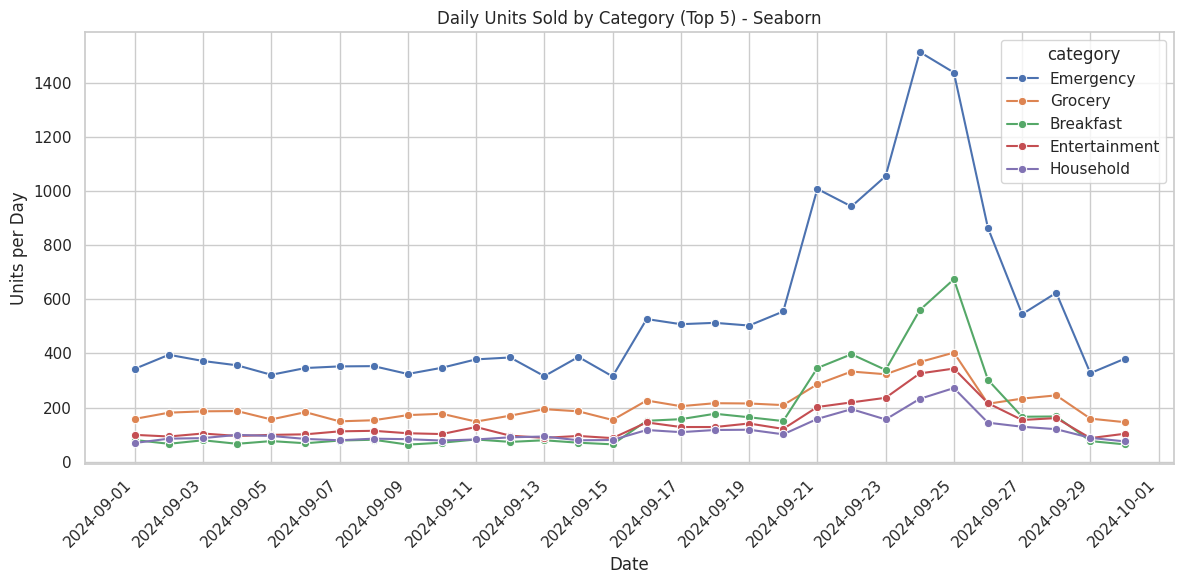

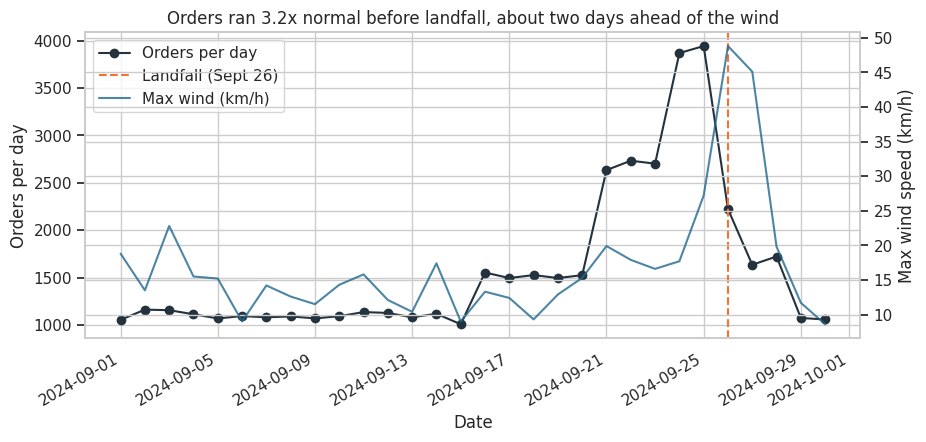

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [10]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': False,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': 'cleaning not in proper format',        # an integer
    'decisions_logged': 'cleaning not in proper format',           # how many entries in your log
    'canonical_products': 20,         # distinct products after consolidation
    'weather_api_rows': 30,           # rows returned by your API call
    'notebook_runs_clean': True,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  FAIL - charter_committed = False
PROGRESS (fill in what you have)
  done - rows_after_cleaning = cleaning not in proper format
  done - decisions_logged = cleaning not in proper format
  done - canonical_products = 20
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: False
progress items done: 5 of 5


False

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** The most likely thing that goes wrong or takes up the most amount of time is getting the cleaning process into a single function and getting the log running properly. I (Michael) have not had to use functions in cleaning before and it will take some time learning how to do it. Same with the cleaning log.



**Plan, with an owner and a date:** Michael is taking care of it. I will look at one of the old notebooks that included a cleaning log and I will look at an old notebook that has the cleaning pipeline defined as a function. I will do my best to have this done by Wedneaday

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | draft answer | Michael |
| Q2 SKU consolidation | draft answer | Michael |
| Q3 weather correlation | draft answer | Michael |
| Q4 store and geography | in progress |Michael |
| Q5 signal or artifact | not started | Fabi |

I want to note that it says Michael owns 4 of the answers, but the analysis for the answers will mainly be done by Sam and Fabi. I am just preparing the code for the analysis. The work is being distributed fairly.

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.